# Regional HAB Forecasting with Gradient Boosting

This notebook develops and evaluates a **regional next-week harmful algal bloom (HAB) forecasting system**.

### Models compared

1. Persistence baseline
2. Current tuned LightGBM
3. More regularized LightGBM
4. CatBoost
5. XGBoost
6. Two-threshold LightGBM

### Final system

1. **Tuned LightGBM** — primary next-week HAB severity forecast (`Class 0`, `Class 1`, or `Class 2`)
2. **CatBoost early-warning layer** — a more sensitive warning based on `P(Class 1) + P(Class 2)`
3. **Persistence** — baseline comparison

### Main evaluation priorities

- Onset recall
- Severe bloom misses
- False alarms
- Macro F1
- Balanced accuracy
- Time-aware historical backtesting

Model selection is performed using data through **2024**. The **2025 test set is reserved for final reporting** and is not used to tune the final models or early-warning threshold.



## 1. Setup


In [ ]:
%pip install -q lightgbm catboost xgboost

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.utils.class_weight import compute_sample_weight

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

print("Imports loaded successfully.")

Imports loaded successfully.


## 2. Load and Prepare the Regional Dataset

The notebook first checks the project-relative dataset path. If it is not found,
it falls back to the local Mac path used during development.


In [53]:
PROJECT_DATA_PATH = Path("data/final/model_table_weekly_fe_reduced.parquet")
LOCAL_FALLBACK_PATH = Path(
    "/Users/mohammedchowdhury/Desktop/BTT/AI_BTT copy/"
    "Biointerphase-1B-copy/data/final/model_table_weekly_fe_reduced.parquet"
)

if PROJECT_DATA_PATH.exists():
    DATA_PATH = PROJECT_DATA_PATH
elif LOCAL_FALLBACK_PATH.exists():
    DATA_PATH = LOCAL_FALLBACK_PATH
else:
    raise FileNotFoundError(
        "Could not find model_table_weekly_fe_reduced.parquet. "
        "Update PROJECT_DATA_PATH or LOCAL_FALLBACK_PATH."
    )

df = pd.read_parquet(DATA_PATH)

print("Dataset loaded:", DATA_PATH)
print("Shape:", df.shape)
print("Columns:", len(df.columns))


Dataset loaded: /Users/mohammedchowdhury/Desktop/BTT/AI_BTT copy/Biointerphase-1B-copy/data/final/model_table_weekly_fe_reduced.parquet
Shape: (595, 104)
Columns: 104


### Target Definition

Only rows with a known `y_class` are used for supervised modeling.

- **Class 0 — Low / No Bloom:** < 5,000 cells/L
- **Class 1 — Elevated Risk:** 5,000–99,999 cells/L
- **Class 2 — Severe / Confirmed Bloom:** ≥ 100,000 cells/L


In [54]:
model_df = df[df["y_class"].notna()].copy()
model_df["y_class"] = model_df["y_class"].astype(int)

print("Labeled rows:", len(model_df))
print()
print("Class counts:")
display(model_df["y_class"].value_counts().sort_index())

print()
print("Split counts:")
display(model_df["split"].value_counts())

Labeled rows: 486

Class counts:


y_class
0    286
1     65
2    135
Name: count, dtype: int64


Split counts:


split
train       364
validate     52
test         52
holdout      18
Name: count, dtype: int64

## 3. Core Features and Time-Based Split


### Core 12 Regional Features

All candidate model families use the same 12 core features so that the model comparison is fair.


In [55]:
regional_core = [
    "last_class",
    "last_log_cells",
    "last_class_prev",
    "last_log_cells_chg1",
    "weeks_since_obs",
    "class_max_4wk",
    "n_habsos_samples",
    "weeks_since_bloom",
    "pos_weeks_12wk",
    "class_run_weeks",
    "season_sin",
    "season_cos"
]

missing_features = [c for c in regional_core if c not in model_df.columns]

if missing_features:
    raise ValueError(f"Missing features: {missing_features}")

print("Using", len(regional_core), "features:")
for feature in regional_core:
    print("-", feature)

Using 12 features:
- last_class
- last_log_cells
- last_class_prev
- last_log_cells_chg1
- weeks_since_obs
- class_max_4wk
- n_habsos_samples
- weeks_since_bloom
- pos_weeks_12wk
- class_run_weeks
- season_sin
- season_cos


### Training and Validation Split

- **Training:** target years through 2023
- **Validation:** 2024
- **Final test:** 2025, held back until model design is locked


In [56]:
X = model_df[regional_core].copy()
y = model_df["y_class"].copy()

train_mask = model_df["split"] == "train"
val_mask = model_df["split"] == "validate"

X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_val = X.loc[val_mask].copy()
y_val = y.loc[val_mask].copy()

val_rows = model_df.loc[val_mask].copy()

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print()
print("Training classes:")
display(y_train.value_counts().sort_index())

print()
print("Validation classes:")
display(y_val.value_counts().sort_index())

Training shape: (364, 12)
Validation shape: (52, 12)

Training classes:


y_class
0    185
1     59
2    120
Name: count, dtype: int64


Validation classes:


y_class
0    38
1     5
2     9
Name: count, dtype: int64

## 4. Shared Evaluation Metrics

Every model is evaluated with the same function.

**Onset recall:** a true onset occurs when the previous class is 0 and the next week's true class becomes 1 or 2.

**Bloom miss:** a true Class 2 severe bloom is predicted as Class 0.

**False alarm:** a true Class 0 week is predicted as Class 1 or 2.

**Cost scores:** severe bloom misses are penalized more heavily than false alarms.

- 2:1 cost = `2 × bloom misses + false alarms`
- 3:1 cost = `3 × bloom misses + false alarms`

Lower cost is better.


In [57]:
def evaluate_model(model_name, y_true, y_pred, rows):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred).astype(int)
    previous_class = rows["last_class"].to_numpy()

    # Standard metrics
    accuracy = accuracy_score(y_true, y_pred)
    balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

    macro_precision = precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    macro_recall = recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    weighted_precision = precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    weighted_recall = recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    weighted_f1 = f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    )

    # Onset = previous class 0, next week becomes class 1 or 2
    onset_mask = (previous_class == 0) & (y_true >= 1)
    onset_total = int(onset_mask.sum())
    onsets_caught = int((y_pred[onset_mask] >= 1).sum())

    onset_recall = (
        onsets_caught / onset_total
        if onset_total > 0
        else np.nan
    )

    # Severe bloom miss = true 2 predicted 0
    bloom_misses = int(
        ((y_true == 2) & (y_pred == 0)).sum()
    )

    # False alarm = true 0 predicted 1 or 2
    false_alarms = int(
        ((y_true == 0) & (y_pred >= 1)).sum()
    )

    cost_2to1 = 2 * bloom_misses + false_alarms
    cost_3to1 = 3 * bloom_misses + false_alarms

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Balanced_Accuracy": balanced_accuracy,
        "Macro_Precision": macro_precision,
        "Macro_Recall": macro_recall,
        "Macro_F1": macro_f1,
        "Weighted_Precision": weighted_precision,
        "Weighted_Recall": weighted_recall,
        "Weighted_F1": weighted_f1,
        "Onset_Total": onset_total,
        "Onsets_Caught": onsets_caught,
        "Onset_Recall": onset_recall,
        "Bloom_Misses": bloom_misses,
        "False_Alarms": false_alarms,
        "Cost_2to1": cost_2to1,
        "Cost_3to1": cost_3to1
    }


def show_confusion_matrix(model_name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    cm_df = pd.DataFrame(
        cm,
        index=["Actual 0", "Actual 1", "Actual 2"],
        columns=["Predicted 0", "Predicted 1", "Predicted 2"]
    )

    print(model_name)
    display(cm_df)

    return cm_df

## 5. Persistence Baseline

Persistence predicts that next week will have the same class as the most recently observed class.
This provides a strong baseline for a temporally persistent HAB process.


In [58]:
y_val_pred_persistence = X_val["last_class"].astype(int).to_numpy()

persistence_metrics = evaluate_model(
    "Persistence Baseline",
    y_val,
    y_val_pred_persistence,
    val_rows
)

display(pd.DataFrame([persistence_metrics]).round(3))
show_confusion_matrix(
    "Persistence Baseline — 2024 Validation",
    y_val,
    y_val_pred_persistence
)

,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Persistence Baseline,0.846,0.613,0.633,0.613,0.622,0.842,0.846,0.844,2,0,0.0,0,1,1,1


Persistence Baseline — 2024 Validation


,Predicted 0,Predicted 1,Predicted 2
Actual 0,37,1,0
Actual 1,2,1,2
Actual 2,0,3,6


,Predicted 0,Predicted 1,Predicted 2
Actual 0,37,1,0
Actual 1,2,1,2
Actual 2,0,3,6


## 6. Candidate Boosting Models

Several boosting approaches are compared on the same 2024 validation set.


### 6.1 Tuned LightGBM — Primary Candidate


In [59]:
current_lgbm = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    learning_rate=0.03,
    max_depth=5,
    n_estimators=100,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

current_lgbm.fit(X_train, y_train)

y_val_pred_current_lgbm = current_lgbm.predict(X_val)

current_lgbm_metrics = evaluate_model(
    "Current Tuned LightGBM",
    y_val,
    y_val_pred_current_lgbm,
    val_rows
)

display(pd.DataFrame([current_lgbm_metrics]).round(3))
show_confusion_matrix(
    "Current Tuned LightGBM — 2024 Validation",
    y_val,
    y_val_pred_current_lgbm
)

,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Current Tuned LightGBM,0.865,0.737,0.702,0.737,0.717,0.881,0.865,0.872,2,1,0.5,0,3,3,3


Current Tuned LightGBM — 2024 Validation


,Predicted 0,Predicted 1,Predicted 2
Actual 0,35,3,0
Actual 1,1,2,2
Actual 2,0,1,8


,Predicted 0,Predicted 1,Predicted 2
Actual 0,35,3,0
Actual 1,1,2,2
Actual 2,0,1,8


### 6.2 Regularized LightGBM

This experiment tests whether stronger regularization improves generalization.


In [60]:
regularized_lgbm = LGBMClassifier(
    objective="multiclass",
    num_class=3,

    learning_rate=0.03,
    n_estimators=180,

    num_leaves=7,
    max_depth=4,
    min_child_samples=25,

    reg_alpha=0.5,
    reg_lambda=1.0,

    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,

    class_weight="balanced",

    random_state=42,
    verbosity=-1
)

regularized_lgbm.fit(X_train, y_train)

y_val_pred_regularized = regularized_lgbm.predict(X_val)

regularized_lgbm_metrics = evaluate_model(
    "Regularized LightGBM",
    y_val,
    y_val_pred_regularized,
    val_rows
)

display(pd.DataFrame([regularized_lgbm_metrics]).round(3))
show_confusion_matrix(
    "Regularized LightGBM — 2024 Validation",
    y_val,
    y_val_pred_regularized
)

,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Regularized LightGBM,0.846,0.67,0.649,0.67,0.658,0.849,0.846,0.847,2,0,0.0,0,3,3,3


Regularized LightGBM — 2024 Validation


,Predicted 0,Predicted 1,Predicted 2
Actual 0,35,3,0
Actual 1,2,1,2
Actual 2,0,1,8


,Predicted 0,Predicted 1,Predicted 2
Actual 0,35,3,0
Actual 1,2,1,2
Actual 2,0,1,8


### 6.3 CatBoost

CatBoost is evaluated as an alternative boosting model and later as a sensitive early-warning layer.
Balanced class weights are used because Class 1 is relatively rare.


In [62]:
catboost_model = CatBoostClassifier(
    loss_function="MultiClass",
    iterations=300,
    learning_rate=0.03,
    depth=5,
    l2_leaf_reg=5,
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False
)

catboost_model.fit(X_train, y_train)

y_val_pred_catboost = (
    catboost_model
    .predict(X_val)
    .reshape(-1)
    .astype(int)
)

catboost_metrics = evaluate_model(
    "CatBoost",
    y_val,
    y_val_pred_catboost,
    val_rows
)

display(pd.DataFrame([catboost_metrics]).round(3))
show_confusion_matrix(
    "CatBoost — 2024 Validation",
    y_val,
    y_val_pred_catboost
)

,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,CatBoost,0.846,0.7,0.679,0.7,0.686,0.873,0.846,0.858,2,1,0.5,0,3,3,3


CatBoost — 2024 Validation


,Predicted 0,Predicted 1,Predicted 2
Actual 0,35,3,0
Actual 1,1,2,2
Actual 2,0,2,7


,Predicted 0,Predicted 1,Predicted 2
Actual 0,35,3,0
Actual 1,1,2,2
Actual 2,0,2,7


### 6.4 XGBoost

XGBoost uses class-balanced sample weights so that rarer classes receive more influence during training.


In [63]:
xgb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,

    n_estimators=250,
    learning_rate=0.03,

    max_depth=4,
    min_child_weight=4,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.3,
    reg_lambda=1.0,

    eval_metric="mlogloss",

    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train,
    sample_weight=xgb_sample_weights
)

y_val_pred_xgb = xgb_model.predict(X_val).astype(int)

xgb_metrics = evaluate_model(
    "XGBoost",
    y_val,
    y_val_pred_xgb,
    val_rows
)

display(pd.DataFrame([xgb_metrics]).round(3))
show_confusion_matrix(
    "XGBoost — 2024 Validation",
    y_val,
    y_val_pred_xgb
)

,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,XGBoost,0.827,0.661,0.637,0.661,0.648,0.845,0.827,0.835,2,0,0.0,0,4,4,4


XGBoost — 2024 Validation


,Predicted 0,Predicted 1,Predicted 2
Actual 0,34,4,0
Actual 1,2,1,2
Actual 2,0,1,8


,Predicted 0,Predicted 1,Predicted 2
Actual 0,34,4,0
Actual 1,2,1,2
Actual 2,0,1,8


### 6.5 Two-Threshold LightGBM

Because the target classes are ordered (`0 → 1 → 2`), this experiment trains two binary models:

- Threshold A: `Class 0` vs `Class 1 or 2`
- Threshold B: `Class 0 or 1` vs `Class 2`

The two probabilities are then combined into a three-class prediction.


In [64]:
# Binary targets

y_train_ge1 = (y_train >= 1).astype(int)
y_train_ge2 = (y_train >= 2).astype(int)

print("Threshold A target: Class 1 or 2")
display(y_train_ge1.value_counts().sort_index())

print()
print("Threshold B target: Class 2")
display(y_train_ge2.value_counts().sort_index())

Threshold A target: Class 1 or 2


y_class
0    185
1    179
Name: count, dtype: int64


Threshold B target: Class 2


y_class
0    244
1    120
Name: count, dtype: int64

In [65]:
# Model A: Is next week Class 1 or Class 2?

threshold_ge1_model = LGBMClassifier(
    objective="binary",
    learning_rate=0.03,
    n_estimators=150,
    num_leaves=7,
    max_depth=4,
    min_child_samples=20,
    reg_lambda=1.0,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

threshold_ge1_model.fit(
    X_train,
    y_train_ge1
)


# Model B: Is next week Class 2?

threshold_ge2_model = LGBMClassifier(
    objective="binary",
    learning_rate=0.03,
    n_estimators=150,
    num_leaves=7,
    max_depth=4,
    min_child_samples=20,
    reg_lambda=1.0,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

threshold_ge2_model.fit(
    X_train,
    y_train_ge2
)

print("Both threshold models trained.")

Both threshold models trained.


#### Combine the Two Threshold Models


In [66]:
p_ge1 = threshold_ge1_model.predict_proba(X_val)[:, 1]
p_ge2 = threshold_ge2_model.predict_proba(X_val)[:, 1]

# Keep the probabilities logically ordered
p_ge2_ordered = np.minimum(p_ge2, p_ge1)

y_val_pred_two_threshold = np.zeros(len(X_val), dtype=int)

# At least Class 1
y_val_pred_two_threshold[p_ge1 >= 0.50] = 1

# Class 2
y_val_pred_two_threshold[p_ge2_ordered >= 0.50] = 2

two_threshold_metrics = evaluate_model(
    "Two-Threshold LightGBM",
    y_val,
    y_val_pred_two_threshold,
    val_rows
)

display(pd.DataFrame([two_threshold_metrics]).round(3))
show_confusion_matrix(
    "Two-Threshold LightGBM — 2024 Validation",
    y_val,
    y_val_pred_two_threshold
)

,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Two-Threshold LightGBM,0.846,0.67,0.649,0.67,0.658,0.849,0.846,0.847,2,0,0.0,0,3,3,3


Two-Threshold LightGBM — 2024 Validation


,Predicted 0,Predicted 1,Predicted 2
Actual 0,35,3,0
Actual 1,2,1,2
Actual 2,0,1,8


,Predicted 0,Predicted 1,Predicted 2
Actual 0,35,3,0
Actual 1,2,1,2
Actual 2,0,1,8


## 7. 2024 Validation Model Comparison

The models are compared using the advisor-priority metrics. Onset recall is important,
but it must be interpreted cautiously because the 2024 validation set contains only two onset events.


In [67]:
all_results = pd.DataFrame([
    persistence_metrics,
    current_lgbm_metrics,
    regularized_lgbm_metrics,
    catboost_metrics,
    xgb_metrics,
    two_threshold_metrics
])

metric_columns = [
    "Accuracy",
    "Balanced_Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1",
    "Weighted_Precision",
    "Weighted_Recall",
    "Weighted_F1",
    "Onset_Recall"
]

all_results_display = all_results.copy()
all_results_display[metric_columns] = (
    all_results_display[metric_columns].round(3)
)

all_results_display

,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Persistence Baseline,0.846,0.613,0.633,0.613,0.622,0.842,0.846,0.844,2,0,0.0,0,1,1,1
1,Current Tuned LightGBM,0.865,0.737,0.702,0.737,0.717,0.881,0.865,0.872,2,1,0.5,0,3,3,3
2,Regularized LightGBM,0.846,0.670,0.649,0.670,0.658,0.849,0.846,0.847,2,0,0.0,0,3,3,3
3,CatBoost,0.846,0.700,0.679,0.700,0.686,0.873,0.846,0.858,2,1,0.5,0,3,3,3
4,XGBoost,0.827,0.661,0.637,0.661,0.648,0.845,0.827,0.835,2,0,0.0,0,4,4,4
5,Two-Threshold LightGBM,0.846,0.670,0.649,0.670,0.658,0.849,0.846,0.847,2,0,0.0,0,3,3,3


### Advisor-Priority Metrics


In [68]:
advisor_comparison = all_results[
    [
        "Model",
        "Onset_Total",
        "Onsets_Caught",
        "Onset_Recall",
        "Bloom_Misses",
        "False_Alarms",
        "Cost_2to1",
        "Cost_3to1",
        "Macro_F1",
        "Balanced_Accuracy",
        "Accuracy"
    ]
].copy()

advisor_comparison[
    [
        "Onset_Recall",
        "Macro_F1",
        "Balanced_Accuracy",
        "Accuracy"
    ]
] = advisor_comparison[
    [
        "Onset_Recall",
        "Macro_F1",
        "Balanced_Accuracy",
        "Accuracy"
    ]
].round(3)

advisor_comparison

,Model,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1,Macro_F1,Balanced_Accuracy,Accuracy
0,Persistence Baseline,2,0,0.0,0,1,1,1,0.622,0.613,0.846
1,Current Tuned LightGBM,2,1,0.5,0,3,3,3,0.717,0.737,0.865
2,Regularized LightGBM,2,0,0.0,0,3,3,3,0.658,0.670,0.846
3,CatBoost,2,1,0.5,0,3,3,3,0.686,0.700,0.846
4,XGBoost,2,0,0.0,0,4,4,4,0.648,0.661,0.827
5,Two-Threshold LightGBM,2,0,0.0,0,3,3,3,0.658,0.670,0.846


### Ranking by Early-Warning Priority

Models are ranked first by onset recall, then bloom misses, false alarms, and Macro F1.


In [69]:
advisor_comparison.sort_values(
    by=[
        "Onset_Recall",
        "Bloom_Misses",
        "False_Alarms",
        "Macro_F1"
    ],
    ascending=[
        False,
        True,
        True,
        False
    ]
)

,Model,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1,Macro_F1,Balanced_Accuracy,Accuracy
1,Current Tuned LightGBM,2,1,0.5,0,3,3,3,0.717,0.737,0.865
3,CatBoost,2,1,0.5,0,3,3,3,0.686,0.700,0.846
0,Persistence Baseline,2,0,0.0,0,1,1,1,0.622,0.613,0.846
2,Regularized LightGBM,2,0,0.0,0,3,3,3,0.658,0.670,0.846
5,Two-Threshold LightGBM,2,0,0.0,0,3,3,3,0.658,0.670,0.846
4,XGBoost,2,0,0.0,0,4,4,4,0.648,0.661,0.827


### 2024 Model-Selection Takeaway

The tuned LightGBM provides the strongest overall multiclass validation performance.
CatBoost is the strongest alternative for further early-warning threshold analysis.
Regularized LightGBM, XGBoost, and the two-threshold model do not provide a better overall trade-off.


## 8. Early-Warning Threshold Sensitivity

For early warning, define:

**Risk Probability = P(Class 1) + P(Class 2)**

The normal multiclass decision chooses the class with the largest probability.
The early-warning layer instead raises a warning when the combined risk probability exceeds a chosen threshold.

Lower thresholds increase sensitivity, but can also increase false alarms.
This section compares LightGBM and CatBoost and then performs a finer search around the most promising range.


In [75]:
# ============================================================
# Get class probabilities from the two strongest models
# ============================================================

# LightGBM probabilities
lgbm_val_proba = current_lgbm.predict_proba(X_val)

# CatBoost probabilities
cat_val_proba = catboost_model.predict_proba(X_val)

print("LightGBM probability shape:", lgbm_val_proba.shape)
print("CatBoost probability shape:", cat_val_proba.shape)

LightGBM probability shape: (52, 3)
CatBoost probability shape: (52, 3)


In [76]:
def predict_with_risk_threshold(probabilities, risk_threshold=0.50):
    """
    Convert multiclass probabilities into predictions using
    an early-warning risk threshold.

    Risk probability = P(Class 1) + P(Class 2)

    If risk probability is below the threshold:
        predict Class 0

    If risk probability is above the threshold:
        choose Class 1 or Class 2 based on which has
        the larger probability.
    """

    probabilities = np.asarray(probabilities)

    p0 = probabilities[:, 0]
    p1 = probabilities[:, 1]
    p2 = probabilities[:, 2]

    risk_probability = p1 + p2

    predictions = np.zeros(len(probabilities), dtype=int)

    # Rows considered risky
    risky = risk_probability >= risk_threshold

    # Among risky rows, choose between Class 1 and Class 2
    predictions[risky] = np.where(
        p2[risky] > p1[risky],
        2,
        1
    )

    return predictions

In [77]:
thresholds = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60
]

In [78]:
lgbm_threshold_results = []

for threshold in thresholds:

    preds = predict_with_risk_threshold(
        lgbm_val_proba,
        risk_threshold=threshold
    )

    metrics = evaluate_model(
        model_name=f"LightGBM threshold={threshold:.2f}",
        y_true=y_val,
        y_pred=preds,
        rows=val_rows
    )

    metrics["Risk_Threshold"] = threshold

    lgbm_threshold_results.append(metrics)


lgbm_threshold_df = pd.DataFrame(
    lgbm_threshold_results
)

display(
    lgbm_threshold_df[
        [
            "Risk_Threshold",
            "Accuracy",
            "Balanced_Accuracy",
            "Macro_F1",
            "Onset_Total",
            "Onsets_Caught",
            "Onset_Recall",
            "Bloom_Misses",
            "False_Alarms",
            "Cost_2to1",
            "Cost_3to1"
        ]
    ].round(3)
)

,Risk_Threshold,Accuracy,Balanced_Accuracy,Macro_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,0.20,0.558,0.654,0.552,2,2,1.0,0,20,20,20
1,0.25,0.635,0.689,0.605,2,2,1.0,0,16,16,16
2,0.30,0.692,0.716,0.636,2,2,1.0,0,13,13,13
3,0.35,0.712,0.724,0.647,2,2,1.0,0,12,12,12
4,0.40,0.769,0.751,0.680,2,2,1.0,0,9,9,9
5,0.45,0.827,0.719,0.689,2,1,0.5,0,5,5,5
6,0.50,0.846,0.728,0.702,2,1,0.5,0,4,4,4
7,0.55,0.827,0.661,0.648,2,0,0.0,0,4,4,4
8,0.60,0.846,0.670,0.658,2,0,0.0,0,3,3,3


In [79]:
cat_threshold_results = []

for threshold in thresholds:

    preds = predict_with_risk_threshold(
        cat_val_proba,
        risk_threshold=threshold
    )

    metrics = evaluate_model(
        model_name=f"CatBoost threshold={threshold:.2f}",
        y_true=y_val,
        y_pred=preds,
        rows=val_rows
    )

    metrics["Risk_Threshold"] = threshold

    cat_threshold_results.append(metrics)


cat_threshold_df = pd.DataFrame(
    cat_threshold_results
)

display(
    cat_threshold_df[
        [
            "Risk_Threshold",
            "Accuracy",
            "Balanced_Accuracy",
            "Macro_F1",
            "Onset_Total",
            "Onsets_Caught",
            "Onset_Recall",
            "Bloom_Misses",
            "False_Alarms",
            "Cost_2to1",
            "Cost_3to1"
        ]
    ].round(3)
)

,Risk_Threshold,Accuracy,Balanced_Accuracy,Macro_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,0.20,0.442,0.573,0.486,2,2,1.0,0,25,25,25
1,0.25,0.577,0.635,0.561,2,2,1.0,0,18,18,18
2,0.30,0.692,0.687,0.621,2,2,1.0,0,12,12,12
3,0.35,0.808,0.740,0.689,2,2,1.0,0,6,6,6
4,0.40,0.808,0.682,0.660,2,1,0.5,0,5,5,5
5,0.45,0.808,0.682,0.660,2,1,0.5,0,5,5,5
6,0.50,0.827,0.691,0.672,2,1,0.5,0,4,4,4
7,0.55,0.846,0.700,0.686,2,1,0.5,0,3,3,3
8,0.60,0.827,0.633,0.631,2,0,0.0,0,3,3,3


In [84]:
fine_thresholds = np.arange(0.30, 0.451, 0.01)

In [85]:
fine_cat_results = []

for threshold in fine_thresholds:

    preds = predict_with_risk_threshold(
        cat_val_proba,
        risk_threshold=threshold
    )

    metrics = evaluate_model(
        model_name=f"CatBoost threshold={threshold:.2f}",
        y_true=y_val,
        y_pred=preds,
        rows=val_rows
    )

    metrics["Risk_Threshold"] = threshold
    fine_cat_results.append(metrics)

fine_cat_df = pd.DataFrame(fine_cat_results)

fine_cat_df[
    [
        "Risk_Threshold",
        "Onsets_Caught",
        "Onset_Recall",
        "Bloom_Misses",
        "False_Alarms",
        "Macro_F1",
        "Balanced_Accuracy",
        "Cost_2to1",
        "Cost_3to1"
    ]
].round(3)

,Risk_Threshold,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Macro_F1,Balanced_Accuracy,Cost_2to1,Cost_3to1
0,0.30,2,1.0,0,12,0.621,0.687,12,12
1,0.31,2,1.0,0,11,0.631,0.696,11,11
2,0.32,2,1.0,0,10,0.642,0.705,10,10
3,0.33,2,1.0,0,8,0.664,0.722,8,8
4,0.34,2,1.0,0,6,0.689,0.740,6,6
5,0.35,2,1.0,0,6,0.689,0.740,6,6
6,0.36,2,1.0,0,5,0.702,0.749,5,5
7,0.37,2,1.0,0,5,0.702,0.749,5,5
8,0.38,2,1.0,0,5,0.702,0.749,5,5
9,0.39,2,1.0,0,5,0.702,0.749,5,5


In [86]:
fine_lgbm_results = []

for threshold in fine_thresholds:

    preds = predict_with_risk_threshold(
        lgbm_val_proba,
        risk_threshold=threshold
    )

    metrics = evaluate_model(
        model_name=f"LightGBM threshold={threshold:.2f}",
        y_true=y_val,
        y_pred=preds,
        rows=val_rows
    )

    metrics["Risk_Threshold"] = threshold
    fine_lgbm_results.append(metrics)

fine_lgbm_df = pd.DataFrame(fine_lgbm_results)

fine_lgbm_df[
    [
        "Risk_Threshold",
        "Onsets_Caught",
        "Onset_Recall",
        "Bloom_Misses",
        "False_Alarms",
        "Macro_F1",
        "Balanced_Accuracy",
        "Cost_2to1",
        "Cost_3to1"
    ]
].round(3)

,Risk_Threshold,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Macro_F1,Balanced_Accuracy,Cost_2to1,Cost_3to1
0,0.30,2,1.0,0,13,0.636,0.716,13,13
1,0.31,2,1.0,0,13,0.636,0.716,13,13
2,0.32,2,1.0,0,13,0.636,0.716,13,13
3,0.33,2,1.0,0,12,0.647,0.724,12,12
4,0.34,2,1.0,0,12,0.647,0.724,12,12
5,0.35,2,1.0,0,12,0.647,0.724,12,12
6,0.36,2,1.0,0,9,0.680,0.751,9,9
7,0.37,2,1.0,0,9,0.680,0.751,9,9
8,0.38,2,1.0,0,9,0.680,0.751,9,9
9,0.39,2,1.0,0,9,0.680,0.751,9,9


### Threshold Sensitivity Takeaway

On the single 2024 validation year, CatBoost can catch both observed onset events at lower thresholds.
However, only two onsets occur in 2024, so an apparently strong threshold may be unstable.
The next section therefore uses historical expanding-year backtesting before retaining a candidate operating threshold.


## 9. Historical Backtesting of the CatBoost Warning Threshold

To avoid choosing a threshold from only two 2024 onset events, CatBoost is backtested across
2020–2024.

For each validation year:

1. train only on earlier observations,
2. leave a four-week gap before the validation year,
3. generate out-of-year probabilities,
4. combine all historical validation predictions,
5. evaluate threshold sensitivity.

The 2025 test year remains excluded from threshold selection.


In [87]:
# Make sure dates are real datetime values

model_df["target_week"] = pd.to_datetime(model_df["target_week"])
model_df["target_year"] = model_df["target_year"].astype(int)

print(
    model_df[
        ["target_week", "target_year", "y_class"]
    ]
    .sort_values("target_week")
    .head()
)

  target_week  target_year  y_class
0  2015-01-12         2015        0
1  2015-01-19         2015        0
2  2015-01-26         2015        0
3  2015-02-02         2015        0
4  2015-02-09         2015        0


In [88]:
candidate_validation_years = [
    2020,
    2021,
    2022,
    2023,
    2024
]

print("Historical validation years:")
print(candidate_validation_years)

Historical validation years:
[2020, 2021, 2022, 2023, 2024]


In [89]:
historical_predictions = []

for validation_year in candidate_validation_years:

    print("=" * 70)
    print("Validation year:", validation_year)

    # --------------------------------------------------------
    # Validation rows for this year
    # --------------------------------------------------------

    year_val_mask = (
        model_df["target_year"] == validation_year
    )

    year_val = model_df.loc[year_val_mask].copy()

    if len(year_val) == 0:
        print("No labeled rows. Skipping.")
        continue


    # --------------------------------------------------------
    # 4-week embargo
    # --------------------------------------------------------

    validation_start = year_val["target_week"].min()

    train_cutoff = (
        validation_start
        - pd.Timedelta(weeks=4)
    )


    # Train only on rows before the cutoff
    year_train_mask = (
        model_df["target_week"] < train_cutoff
    )

    year_train = model_df.loc[
        year_train_mask
    ].copy()


    # --------------------------------------------------------
    # Safety checks
    # --------------------------------------------------------

    train_classes = sorted(
        year_train["y_class"].unique()
    )

    print("Training rows:", len(year_train))
    print("Validation rows:", len(year_val))
    print("Training classes:", train_classes)

    # We need all three classes for a fair multiclass model
    if len(train_classes) < 3:
        print(
            "Training data does not contain all 3 classes. "
            "Skipping this year."
        )
        continue


    # --------------------------------------------------------
    # Features and target
    # --------------------------------------------------------

    X_year_train = year_train[regional_core]
    y_year_train = year_train["y_class"]

    X_year_val = year_val[regional_core]
    y_year_val = year_val["y_class"]


    # --------------------------------------------------------
    # Train CatBoost
    # Same model settings as before
    # --------------------------------------------------------

    year_catboost = CatBoostClassifier(
        loss_function="MultiClass",
        iterations=300,
        learning_rate=0.03,
        depth=5,
        l2_leaf_reg=5,
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False
    )

    year_catboost.fit(
        X_year_train,
        y_year_train
    )


    # --------------------------------------------------------
    # Predict probabilities
    # --------------------------------------------------------

    year_proba = year_catboost.predict_proba(
        X_year_val
    )

    # Risk probability =
    # P(Class 1) + P(Class 2)
    risk_probability = (
        year_proba[:, 1]
        + year_proba[:, 2]
    )


    # --------------------------------------------------------
    # Save each prediction
    # --------------------------------------------------------

    fold_results = pd.DataFrame({
        "target_week": year_val["target_week"].to_numpy(),
        "validation_year": validation_year,

        "y_true": y_year_val.to_numpy(),

        "last_class": (
            year_val["last_class"]
            .to_numpy()
        ),

        "p_class0": year_proba[:, 0],
        "p_class1": year_proba[:, 1],
        "p_class2": year_proba[:, 2],

        "risk_probability": risk_probability
    })

    historical_predictions.append(
        fold_results
    )

    print("Saved predictions for", validation_year)

Validation year: 2020
Training rows: 256
Validation rows: 52
Training classes: [np.int64(0), np.int64(1), np.int64(2)]
Saved predictions for 2020
Validation year: 2021
Training rows: 308
Validation rows: 27
Training classes: [np.int64(0), np.int64(1), np.int64(2)]
Saved predictions for 2021
Validation year: 2022
Training rows: 339
Validation rows: 8
Training classes: [np.int64(0), np.int64(1), np.int64(2)]
Saved predictions for 2022
Validation year: 2023
Training rows: 346
Validation rows: 17
Training classes: [np.int64(0), np.int64(1), np.int64(2)]
Saved predictions for 2023
Validation year: 2024
Training rows: 363
Validation rows: 52
Training classes: [np.int64(0), np.int64(1), np.int64(2)]
Saved predictions for 2024


In [90]:
historical_pred_df = pd.concat(
    historical_predictions,
    ignore_index=True
)

print(
    "Total historical validation predictions:",
    len(historical_pred_df)
)

print()
print("Rows by year:")

display(
    historical_pred_df[
        "validation_year"
    ]
    .value_counts()
    .sort_index()
)

Total historical validation predictions: 156

Rows by year:


validation_year
2020    52
2021    27
2022     8
2023    17
2024    52
Name: count, dtype: int64

In [102]:
historical_pred_df["is_onset"] = (
    (historical_pred_df["last_class"] == 0)
    &
    (historical_pred_df["y_true"] >= 1)
)

onsets_by_year = (
    historical_pred_df
    .groupby("validation_year")["is_onset"]
    .agg(["sum", "count"])
)

onsets_by_year.columns = [
    "Onset_Weeks",
    "Validation_Rows"
]

display(onsets_by_year)

print(
    "Total historical onset weeks:",
    historical_pred_df["is_onset"].sum()
)

,Onset_Weeks,Validation_Rows
validation_year,,
2020,6,52
2021,2,27
2022,1,8
2023,2,17
2024,2,52


Total historical onset weeks: 13


In [103]:
def evaluate_historical_threshold(
    df,
    threshold
):

    y_true = df["y_true"].to_numpy()

    risk_probability = (
        df["risk_probability"].to_numpy()
    )

    p1 = df["p_class1"].to_numpy()
    p2 = df["p_class2"].to_numpy()

    previous_class = (
        df["last_class"].to_numpy()
    )


    # --------------------------------------------------------
    # Turn probability into a class prediction
    # --------------------------------------------------------

    y_pred = np.zeros(
        len(df),
        dtype=int
    )

    risky = (
        risk_probability >= threshold
    )

    y_pred[risky] = np.where(
        p2[risky] > p1[risky],
        2,
        1
    )


    # --------------------------------------------------------
    # Standard metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    # --------------------------------------------------------
    # Onset metrics
    # --------------------------------------------------------

    onset_mask = (
        (previous_class == 0)
        &
        (y_true >= 1)
    )

    onset_total = int(
        onset_mask.sum()
    )

    onsets_caught = int(
        (
            y_pred[onset_mask] >= 1
        ).sum()
    )

    missed_onsets = (
        onset_total
        - onsets_caught
    )

    onset_recall = (
        onsets_caught / onset_total
        if onset_total > 0
        else np.nan
    )


    # --------------------------------------------------------
    # Bloom misses
    # True Class 2 predicted as Class 0
    # --------------------------------------------------------

    bloom_misses = int(
        (
            (y_true == 2)
            &
            (y_pred == 0)
        ).sum()
    )


    # --------------------------------------------------------
    # False alarms
    # True Class 0 predicted as Class 1 or 2
    # --------------------------------------------------------

    false_alarms = int(
        (
            (y_true == 0)
            &
            (y_pred >= 1)
        ).sum()
    )


    # --------------------------------------------------------
    # Original bloom-miss cost
    # --------------------------------------------------------

    cost_2to1 = (
        2 * bloom_misses
        + false_alarms
    )

    cost_3to1 = (
        3 * bloom_misses
        + false_alarms
    )


    # --------------------------------------------------------
    # NEW: early-warning cost
    #
    # Missed onsets cost more than false alarms
    # --------------------------------------------------------

    early_warning_cost_2to1 = (
        2 * missed_onsets
        + false_alarms
    )

    early_warning_cost_3to1 = (
        3 * missed_onsets
        + false_alarms
    )


    return {
        "Risk_Threshold": threshold,

        "Validation_Rows": len(df),

        "Onset_Total": onset_total,
        "Onsets_Caught": onsets_caught,
        "Missed_Onsets": missed_onsets,
        "Onset_Recall": onset_recall,

        "Bloom_Misses": bloom_misses,
        "False_Alarms": false_alarms,

        "Cost_2to1": cost_2to1,
        "Cost_3to1": cost_3to1,

        "Early_Warning_Cost_2to1":
            early_warning_cost_2to1,

        "Early_Warning_Cost_3to1":
            early_warning_cost_3to1,

        "Macro_F1": macro_f1,
        "Balanced_Accuracy":
            balanced_accuracy,
        "Accuracy": accuracy
    }

In [104]:
historical_thresholds = np.arange(
    0.15,
    0.351,
    0.01
)

historical_threshold_results = []

for threshold in historical_thresholds:

    result = evaluate_historical_threshold(
        historical_pred_df,
        threshold
    )

    historical_threshold_results.append(
        result
    )

historical_threshold_df = pd.DataFrame(
    historical_threshold_results
)

In [105]:
historical_final_table = historical_threshold_df[
    [
        "Risk_Threshold",

        "Onset_Total",
        "Onsets_Caught",
        "Missed_Onsets",
        "Onset_Recall",

        "Bloom_Misses",
        "False_Alarms",

        "Early_Warning_Cost_2to1",
        "Early_Warning_Cost_3to1",

        "Macro_F1",
        "Balanced_Accuracy",
        "Accuracy"
    ]
].copy()

display(
    historical_final_table.round(3)
)

,Risk_Threshold,Onset_Total,Onsets_Caught,Missed_Onsets,Onset_Recall,Bloom_Misses,False_Alarms,Early_Warning_Cost_2to1,Early_Warning_Cost_3to1,Macro_F1,Balanced_Accuracy,Accuracy
0,0.15,13,12,1,0.923,0,79,81,82,0.460,0.558,0.397
1,0.16,13,12,1,0.923,0,76,78,79,0.476,0.568,0.417
2,0.17,13,12,1,0.923,0,73,75,76,0.492,0.578,0.436
3,0.18,13,11,2,0.846,0,72,76,78,0.492,0.571,0.436
4,0.19,13,10,3,0.769,0,66,72,75,0.515,0.581,0.468
5,0.20,13,10,3,0.769,0,64,70,73,0.524,0.587,0.481
6,0.21,13,10,3,0.769,0,61,67,70,0.538,0.597,0.500
7,0.22,13,10,3,0.769,0,56,62,65,0.560,0.614,0.532
8,0.23,13,10,3,0.769,0,55,61,64,0.564,0.618,0.538
9,0.24,13,10,3,0.769,0,51,57,60,0.581,0.631,0.564


### Historical Threshold Takeaway

The historical backtest contains **13 onset weeks**. Lower thresholds increase onset recall,
but the improvement comes with a large increase in false alarms.

For example, very low thresholds can recover most onset events but create dozens of false alarms.
Therefore, `0.35` is retained only as a **candidate early-warning operating threshold**, not as a universally optimal cutoff.


## 10. Historical Comparison: Tuned LightGBM vs CatBoost Early Warning

The tuned LightGBM is backtested on the same historical folds so the primary forecast
and the CatBoost warning layer can be compared on the same 13 onset events.


In [106]:
historical_lgbm_predictions = []

for validation_year in candidate_validation_years:

    print("=" * 70)
    print("Validation year:", validation_year)

    year_val = model_df[
        model_df["target_year"] == validation_year
    ].copy()

    if len(year_val) == 0:
        continue

    validation_start = year_val["target_week"].min()

    train_cutoff = (
        validation_start
        - pd.Timedelta(weeks=4)
    )

    year_train = model_df[
        model_df["target_week"] < train_cutoff
    ].copy()

    if year_train["y_class"].nunique() < 3:
        continue

    X_year_train = year_train[regional_core]
    y_year_train = year_train["y_class"]

    X_year_val = year_val[regional_core]

    # Same tuned LightGBM settings
    year_lgbm = LGBMClassifier(
        objective="multiclass",
        num_class=3,
        learning_rate=0.03,
        max_depth=5,
        n_estimators=100,
        num_leaves=15,
        class_weight="balanced",
        random_state=42,
        verbosity=-1
    )

    year_lgbm.fit(
        X_year_train,
        y_year_train
    )

    proba = year_lgbm.predict_proba(
        X_year_val
    )

    # Normal multiclass prediction
    predictions = np.argmax(
        proba,
        axis=1
    )

    fold_results = pd.DataFrame({
        "target_week":
            year_val["target_week"].to_numpy(),

        "validation_year":
            validation_year,

        "y_true":
            year_val["y_class"].to_numpy(),

        "last_class":
            year_val["last_class"].to_numpy(),

        "y_pred":
            predictions,

        "risk_probability":
            proba[:, 1] + proba[:, 2]
    })

    historical_lgbm_predictions.append(
        fold_results
    )

historical_lgbm_df = pd.concat(
    historical_lgbm_predictions,
    ignore_index=True
)

print(
    "Historical LightGBM predictions:",
    len(historical_lgbm_df)
)

Validation year: 2020
Validation year: 2021
Validation year: 2022
Validation year: 2023
Validation year: 2024
Historical LightGBM predictions: 156


In [107]:
def evaluate_saved_predictions(df):

    y_true = df["y_true"].to_numpy()
    y_pred = df["y_pred"].to_numpy()

    previous_class = (
        df["last_class"].to_numpy()
    )

    onset_mask = (
        (previous_class == 0)
        &
        (y_true >= 1)
    )

    onset_total = int(
        onset_mask.sum()
    )

    onsets_caught = int(
        (y_pred[onset_mask] >= 1).sum()
    )

    missed_onsets = (
        onset_total - onsets_caught
    )

    onset_recall = (
        onsets_caught / onset_total
        if onset_total > 0
        else np.nan
    )

    bloom_misses = int(
        (
            (y_true == 2)
            &
            (y_pred == 0)
        ).sum()
    )

    false_alarms = int(
        (
            (y_true == 0)
            &
            (y_pred >= 1)
        ).sum()
    )

    return {
        "Validation_Rows": len(df),

        "Onset_Total": onset_total,
        "Onsets_Caught": onsets_caught,
        "Missed_Onsets": missed_onsets,
        "Onset_Recall": onset_recall,

        "Bloom_Misses": bloom_misses,
        "False_Alarms": false_alarms,

        "Accuracy":
            accuracy_score(y_true, y_pred),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "Macro_F1":
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
    }


historical_lgbm_metrics = (
    evaluate_saved_predictions(
        historical_lgbm_df
    )
)

pd.DataFrame(
    [historical_lgbm_metrics],
    index=["Tuned LightGBM"]
).round(3)

,Validation_Rows,Onset_Total,Onsets_Caught,Missed_Onsets,Onset_Recall,Bloom_Misses,False_Alarms,Accuracy,Balanced_Accuracy,Macro_F1
Tuned LightGBM,156,13,2,11,0.154,2,23,0.66,0.583,0.586


### Historical Comparison Takeaway

Across the historical folds, CatBoost at the candidate warning threshold detects more onsets
than the normal LightGBM decision rule, but it also produces more false alarms.

This supports using the two models for different purposes:

- **LightGBM:** primary three-class severity forecast
- **CatBoost:** more sensitive early-warning layer


## 11. Final 2025 Test Evaluation

Model design and threshold analysis are now locked using data through 2024.
The 2025 test set is used only for final evaluation.

Locked approaches:

- Persistence baseline
- Tuned LightGBM for the primary three-class forecast
- CatBoost with a `0.35` candidate risk threshold for early warning


In [108]:
# Train on all labeled data through 2024
final_train = model_df[
    model_df["target_year"] <= 2024
].copy()

# Final test year
final_test = model_df[
    model_df["target_year"] == 2025
].copy()

X_final_train = final_train[regional_core]
y_final_train = final_train["y_class"]

X_test_2025 = final_test[regional_core]
y_test_2025 = final_test["y_class"]

print("Final training rows:", len(final_train))
print("2025 test rows:", len(final_test))

print("\n2025 class counts:")
print(y_test_2025.value_counts().sort_index())

Final training rows: 416
2025 test rows: 52

2025 class counts:
y_class
0    45
1     1
2     6
Name: count, dtype: int64


In [109]:
final_catboost = CatBoostClassifier(
    loss_function="MultiClass",
    iterations=300,
    learning_rate=0.03,
    depth=5,
    l2_leaf_reg=5,
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False
)

final_catboost.fit(
    X_final_train,
    y_final_train
)

print("Final CatBoost trained.")

Final CatBoost trained.


In [110]:
cat_test_proba = final_catboost.predict_proba(
    X_test_2025
)

cat_test_risk_probability = (
    cat_test_proba[:, 1]
    + cat_test_proba[:, 2]
)

print(
    "Risk probability range:",
    round(cat_test_risk_probability.min(), 3),
    "to",
    round(cat_test_risk_probability.max(), 3)
)

Risk probability range: 0.044 to 0.986


In [111]:
LOCKED_CAT_THRESHOLD = 0.35

cat_test_pred = predict_with_risk_threshold(
    cat_test_proba,
    risk_threshold=LOCKED_CAT_THRESHOLD
)

print(
    "CatBoost predictions created using threshold:",
    LOCKED_CAT_THRESHOLD
)

CatBoost predictions created using threshold: 0.35


In [112]:
cat_2025_metrics = evaluate_model(
    model_name="CatBoost Early Warning - 2025",
    y_true=y_test_2025,
    y_pred=cat_test_pred,
    rows=final_test
)

cat_2025_df = pd.DataFrame(
    [cat_2025_metrics]
)

display(
    cat_2025_df[
        [
            "Accuracy",
            "Balanced_Accuracy",
            "Macro_F1",
            "Weighted_F1",

            "Onset_Total",
            "Onsets_Caught",
            "Onset_Recall",

            "Bloom_Misses",
            "False_Alarms",

            "Cost_2to1",
            "Cost_3to1"
        ]
    ].round(3)
)

,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,0.904,0.637,0.626,0.932,0,0,NaN,0,4,4,4


In [116]:
def catboost_early_warning_output(
    model,
    X_row,
    threshold=0.35
):
    # Get probabilities for Class 0, 1, and 2
    proba = model.predict_proba(X_row)[0]

    p0 = proba[0]
    p1 = proba[1]
    p2 = proba[2]

    # Combined risk probability
    risk_probability = p1 + p2

    # Decide whether to raise an early warning
    early_warning = risk_probability >= threshold

    # Decide warning level
    if early_warning:
        warning_level = 2 if p2 > p1 else 1
    else:
        warning_level = 0

    print(
        f"HAB Early Warning: {'YES' if early_warning else 'NO'}"
    )

    print(
        f"Risk Probability: {risk_probability:.0%}"
    )

    print(
        f"Warning Level: Class {warning_level}"
    )

    return {
        "HAB_Early_Warning":
            "YES" if early_warning else "NO",

        "Risk_Probability":
            risk_probability,

        "Warning_Level":
            warning_level,

        "Class_0_Probability": p0,
        "Class_1_Probability": p1,
        "Class_2_Probability": p2
    }

In [117]:
sample_week = X_test_2025.iloc[[0]]

result = catboost_early_warning_output(
    final_catboost,
    sample_week,
    threshold=0.35
)

HAB Early Warning: YES
Risk Probability: 96%
Warning Level: Class 2


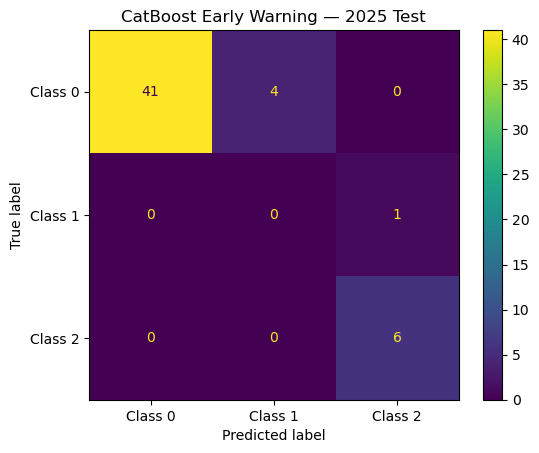

In [114]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test_2025,
    cat_test_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

disp.plot()

plt.title(
    "CatBoost Early Warning — 2025 Test"
)

plt.show()

### CatBoost 2025 Result

CatBoost at the locked `0.35` early-warning threshold achieved **90.4% accuracy** on the
2025 test set, correctly identified all six Class 2 severe-bloom weeks, produced **zero bloom misses**,
and generated **four false alarms**.

The single Class 1 week was conservatively predicted as Class 2.
Because 2025 contained no true onset events, onset recall is undefined for this test year.


## 12. Retrain the Final LightGBM Through 2024

After hyperparameters are locked, the deployable LightGBM is retrained on all labeled observations
through 2024. The 2025 test set is still excluded from training.


In [135]:
# Final training data through 2024
final_train = model_df[
    model_df["target_year"] <= 2024
].copy()

X_final_train = final_train[regional_core]
y_final_train = final_train["y_class"]

print("Final LightGBM training rows:", len(final_train))
print("\nClass counts:")
print(y_final_train.value_counts().sort_index())

Final LightGBM training rows: 416

Class counts:
y_class
0    223
1     64
2    129
Name: count, dtype: int64


In [136]:
final_lgbm = LGBMClassifier(
    objective="multiclass",
    num_class=3,

    learning_rate=0.03,
    max_depth=5,
    n_estimators=100,
    num_leaves=15,

    class_weight="balanced",

    random_state=42,
    verbosity=-1
)

final_lgbm.fit(
    X_final_train,
    y_final_train
)

print("Final LightGBM trained on all data through 2024.")

Final LightGBM trained on all data through 2024.


In [137]:
final_lgbm_test_pred = final_lgbm.predict(
    X_test_2025
)

final_lgbm_2025_metrics = evaluate_model(
    model_name="Final LightGBM - 2025",
    y_true=y_test_2025,
    y_pred=final_lgbm_test_pred,
    rows=final_test
)

pd.DataFrame(
    [final_lgbm_2025_metrics]
).round(3)

,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Final LightGBM - 2025,0.904,0.589,0.611,0.589,0.6,0.962,0.904,0.932,0,0,NaN,0,3,3,3


## 13. Final Model Selection

The final regional system uses two complementary components:

### Primary forecast — Tuned LightGBM
Returns the most likely next-week HAB severity class (`0`, `1`, or `2`).

### Early-warning layer — CatBoost + 0.35 candidate threshold
Computes `P(Class 1) + P(Class 2)` and raises a more sensitive warning when the combined risk reaches the candidate threshold.

Persistence remains the baseline. The candidate threshold is not treated as universally optimal because historical onset behavior varies by year.


In [115]:
final_model_summary = pd.DataFrame([
    {
        "Model": "Persistence Baseline",
        "Role": "Baseline",
        "2024_Macro_F1": 0.622,
        "2024_Balanced_Accuracy": 0.613,
        "2024_Onset_Recall": 0.0,
        "2024_Bloom_Misses": 0,
        "2024_False_Alarms": 1,
        "2025_Accuracy": 0.962,
        "2025_Macro_F1": 0.637,
        "2025_Bloom_Misses": 0,
        "2025_False_Alarms": 1
    },

    {
        "Model": "Tuned LightGBM",
        "Role": "Primary 3-Class Forecast",
        "2024_Macro_F1": 0.717,
        "2024_Balanced_Accuracy": 0.737,
        "2024_Onset_Recall": 0.5,
        "2024_Bloom_Misses": 0,
        "2024_False_Alarms": 3,
        "2025_Accuracy": 0.904,
        "2025_Macro_F1": 0.600,
        "2025_Bloom_Misses": 0,
        "2025_False_Alarms": 3
    },

    {
        "Model": "CatBoost + 0.35 Threshold",
        "Role": "Early-Warning Layer",
        "2024_Macro_F1": 0.689,
        "2024_Balanced_Accuracy": 0.740,
        "2024_Onset_Recall": 1.0,
        "2024_Bloom_Misses": 0,
        "2024_False_Alarms": 6,
        "2025_Accuracy": 0.904,
        "2025_Macro_F1": 0.626,
        "2025_Bloom_Misses": 0,
        "2025_False_Alarms": 4
    }
])

display(final_model_summary)

,Model,Role,2024_Macro_F1,2024_Balanced_Accuracy,2024_Onset_Recall,2024_Bloom_Misses,2024_False_Alarms,2025_Accuracy,2025_Macro_F1,2025_Bloom_Misses,2025_False_Alarms
0,Persistence Baseline,Baseline,0.622,0.613,0.0,0,1,0.962,0.637,0,1
1,Tuned LightGBM,Primary 3-Class Forecast,0.717,0.737,0.5,0,3,0.904,0.600,0,3
2,CatBoost + 0.35 Threshold,Early-Warning Layer,0.689,0.740,1.0,0,6,0.904,0.626,0,4


## 14. Feature Importance and Model Interpretation

Gain importance is used to understand what drove the validation-selected LightGBM model.
The result shows that recent HAB history and seasonality dominate the forecast.


In [121]:
feature_importance_df = pd.DataFrame({
    "Feature": regional_core,
    "Importance": current_lgbm.booster_.feature_importance(
        importance_type="gain"
    )
})

feature_importance_df["Importance_Percent"] = (
    feature_importance_df["Importance"]
    / feature_importance_df["Importance"].sum()
    * 100
)

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance_Percent",
        ascending=False
    )
)

display(
    feature_importance_df.round(2)
)

,Feature,Importance,Importance_Percent
1,last_log_cells,6130.55,59.69
7,weeks_since_bloom,1259.87,12.27
11,season_cos,722.77,7.04
3,last_log_cells_chg1,670.54,6.53
10,season_sin,505.52,4.92
9,class_run_weeks,320.71,3.12
2,last_class_prev,287.94,2.80
6,n_habsos_samples,243.95,2.38
8,pos_weeks_12wk,103.56,1.01
5,class_max_4wk,24.90,0.24


### Feature Importance Interpretation

The tuned LightGBM model relied primarily on recent HAB history.

The most important feature was `last_log_cells`, which accounted for about
59.7% of the model's total gain importance. This indicates that the most recent
observed cell concentration is the strongest predictor of next-week HAB severity.

The second most important feature was `weeks_since_bloom` at about 12.3%,
showing that recent bloom history also plays a major role in forecasting risk.

Seasonal features (`season_cos` and `season_sin`) contributed additional
predictive information, suggesting that the model learned recurring patterns
across the year.

`last_log_cells_chg1` was also important, indicating that recent increases or
decreases in cell concentration help the model distinguish changing bloom
conditions.

Overall, the model depends much more on recent HAB history and seasonality than
on individual environmental variables.

## 15. Environmental Feature Experiments

Environmental feature groups were tested to determine whether they improved next-week forecasting beyond the core HAB-history features.

Groups tested:

- temperature
- chlorophyll
- wind
- nutrients
- rainfall

The **Core 12** model remained strongest overall:

- Accuracy: **0.865**
- Balanced Accuracy: **0.737**
- Macro F1: **0.717**

Among the environmental extensions, **rain** had the highest Macro F1 (`0.673`), with wind close behind (`0.670`), but neither exceeded the core-only model.

This does **not** imply that environmental conditions are biologically unimportant. It means that, in this regional next-week setup, the tested environmental variables did not add enough predictive value beyond recent HAB history to improve validation performance.


In [123]:
environmental_results = pd.DataFrame({
    "Feature_Set": [
        "Core 12",
        "Core + Temperature",
        "Core + Chlorophyll",
        "Core + Wind",
        "Core + Nutrients",
        "Core + Rain",
        "Core + Major Environmental Features"
    ],
    "Accuracy": [
        0.865,
        0.808,
        0.769,
        0.808,
        0.827,
        0.827,
        0.788
    ],
    "Balanced_Accuracy": [
        0.737,
        0.624,
        0.665,
        0.710,
        0.661,
        0.691,
        0.615
    ],
    "Macro_F1": [
        0.717,
        0.615,
        0.638,
        0.670,
        0.648,
        0.673,
        0.604
    ]
})

display(environmental_results)

,Feature_Set,Accuracy,Balanced_Accuracy,Macro_F1
0,Core 12,0.865,0.737,0.717
1,Core + Temperature,0.808,0.624,0.615
2,Core + Chlorophyll,0.769,0.665,0.638
3,Core + Wind,0.808,0.710,0.670
4,Core + Nutrients,0.827,0.661,0.648
5,Core + Rain,0.827,0.691,0.673
6,Core + Major Environmental Features,0.788,0.615,0.604


## 16. Limitations

### Limitations

Although the final models showed useful predictive performance, several
limitations should be considered.

#### 1. Rare onset events
True regional HAB onset events were relatively uncommon.

The 2024 validation set contained only two onset events, and the historical
2020–2024 backtest contained 13 onset events.

Because of this small number of events, onset recall can change substantially
when only one or two additional events are correctly or incorrectly predicted.

#### 2. Class imbalance
Class 1 observations were much less common than Class 0 observations.

This made the intermediate-risk class more difficult for the models to learn
and contributed to lower Class 1 precision and recall.

#### 3. Strong temporal persistence
Recent HAB conditions were highly predictive of future conditions.

This is useful for prediction, but it also explains why the simple persistence
baseline performed strongly during stable periods.

The main challenge is predicting transitions and new bloom development rather
than predicting weeks where conditions remain similar.

#### 4. Environmental features did not improve validation performance
Temperature, chlorophyll, wind, nutrient, and rainfall variables were tested,
but they did not improve the regional validation results.

This does not mean these environmental factors are biologically unimportant.

Their predictive relationships may occur at different time lags, operate at
smaller spatial scales, or be difficult to capture after regional aggregation.

#### 5. Early-warning false alarms
Lowering the CatBoost risk threshold increased onset detection, but also
substantially increased false alarms.

The selected 0.35 threshold should therefore be treated as a candidate
early-warning operating point rather than a universally optimal threshold.

#### 6. Limited final-test onset evaluation
The 2025 test set contained no true regional onset events.

Therefore, the final test year could evaluate classification performance,
severe bloom detection, and false alarms, but could not independently evaluate
onset recall.


Additional data will be especially important for determining whether the
CatBoost early-warning layer consistently detects new bloom development
without producing an excessive number of false alarms.


## 17. Key Findings

1. **Tuned LightGBM was the strongest primary multiclass model.**  
   It achieved the best overall 2024 validation performance, with a Macro F1
   of 0.717 and balanced accuracy of 0.737.

2. **Recent HAB history was more predictive than environmental variables.**  
   `last_log_cells` was the most important LightGBM feature, followed by
   `weeks_since_bloom`.

3. **Environmental feature groups did not improve validation performance.**  
   Temperature, chlorophyll, wind, nutrients, and rainfall were tested, but
   none outperformed the core 12-feature model.

4. **Early-warning sensitivity required a trade-off.**  
   Lowering the CatBoost risk threshold improved onset recall but increased
   false alarms.

5. **Historical backtesting showed that onset prediction remains difficult.**  
   Across 13 historical onset events, CatBoost detected more onsets than the
   tuned LightGBM, but with more false alarms.

6. **CatBoost was useful as a separate early-warning layer.**  
   A candidate risk threshold of 0.35 was retained for a more sensitive warning
   system.

7. **Both final models avoided severe bloom misses on the 2025 test set.**  
   CatBoost correctly identified all six Class 2 weeks and produced four false
   alarms, while tuned LightGBM also produced zero bloom misses with three false
   alarms.

8. **The main forecasting challenge is predicting change, not persistence.**  
   Stable HAB conditions are relatively easy to predict. The harder problem is
   identifying when conditions transition into a new bloom or elevated-risk
   state.


## 18. Final Results Narrative

The regional HAB forecasting analysis compared several boosting approaches,
including LightGBM, CatBoost, XGBoost, regularized LightGBM, and a two-threshold
LightGBM model.

The tuned LightGBM model was selected as the primary next-week severity
classifier. On the 2024 validation set, it achieved an accuracy of 0.865,
balanced accuracy of 0.737, and Macro F1 of 0.717. It also detected one of the
two observed onset events while producing no severe bloom misses.

Feature-importance analysis showed that the model relied primarily on recent
HAB conditions. The strongest feature was `last_log_cells`, followed by
`weeks_since_bloom`, seasonal variables, and recent changes in cell counts.
This indicates that recent bloom history is highly informative for predicting
next-week conditions.

Environmental variables including temperature, chlorophyll, wind, nutrients,
and rainfall were also evaluated. However, none of these feature groups
improved validation performance beyond the core HAB-history features.
Therefore, they were not included in the final LightGBM model.

Because early warning was an important project goal, CatBoost was evaluated as
a separate warning layer. The CatBoost risk score was defined as:

Risk Probability = P(Class 1) + P(Class 2)

Threshold analysis showed that lowering the risk threshold increased onset
detection but also increased false alarms.

Historical backtesting from 2020 through 2024 included 13 onset events.
CatBoost with a candidate threshold of 0.35 detected 6 of the 13 onsets,
compared with 2 of 13 for the tuned LightGBM historical predictions.
However, CatBoost also produced more false alarms.

On the 2025 test set, CatBoost with the 0.35 warning threshold achieved an
accuracy of 0.904, balanced accuracy of 0.637, and Macro F1 of 0.626.
It correctly identified all six Class 2 severe bloom weeks, produced zero
severe bloom misses, and generated four false alarms.

The tuned LightGBM also produced zero severe bloom misses on the 2025 test set,
with three false alarms.

Because no true regional onset events occurred in 2025, onset recall could not
be evaluated on the final test year.

Overall, the final regional system uses:

- Tuned LightGBM for the primary next-week HAB severity prediction.
- CatBoost as a more sensitive early-warning layer.
- Persistence as the baseline comparison.

The results show that stable HAB conditions can be predicted relatively well,
while forecasting transitions into new bloom conditions remains the more
difficult problem.


## 19. Final User-Facing Model Outputs

### Primary LightGBM Forecast

Example:

```text
Predicted Next-Week HAB Class: Class 2
```

### CatBoost Early Warning

Example:

```text
HAB Early Warning: YES
Risk Probability: 42%
Warning Level: Class 1
```

### Class Meanings

- **Class 0 — Low / No Bloom:** < 5,000 cells/L
- **Class 1 — Elevated Risk:** 5,000–99,999 cells/L
- **Class 2 — Severe / Confirmed Bloom:** ≥ 100,000 cells/L


## 20. Save Final Models, Results, and Figures

The final artifacts are stored under `models/boosting_mohammed/`:

- `saved_model/` — deployable models and system configuration
- `results/` — summary CSV files
- `figures/` — presentation-ready figures


In [126]:
from pathlib import Path

BASE_DIR = Path("models/boosting_mohammed")

SAVED_MODEL_DIR = BASE_DIR / "saved_model"
FIGURES_DIR = BASE_DIR / "figures"
RESULTS_DIR = BASE_DIR / "results"

SAVED_MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Folders ready:")
print(SAVED_MODEL_DIR)
print(FIGURES_DIR)
print(RESULTS_DIR)

Folders ready:
models/boosting_mohammed/saved_model
models/boosting_mohammed/figures
models/boosting_mohammed/results


In [138]:
import joblib

joblib.dump(
    final_lgbm,
    SAVED_MODEL_DIR / "tuned_lightgbm_final_through_2024.pkl"
)

print("Saved final LightGBM.")

Saved final LightGBM.


In [140]:
final_catboost.save_model(
    SAVED_MODEL_DIR / "catboost_early_warning_final_through_2024.cbm"
)

print("Saved final CatBoost.")

Saved final CatBoost.


In [139]:
import json

system_config = {
    "primary_model": "tuned_lightgbm_final_through_2024.pkl",

    "primary_model_output": {
        "0": "Low / No Bloom",
        "1": "Elevated Risk",
        "2": "Severe / Confirmed Bloom"
    },

    "early_warning_model":
        "catboost_early_warning_final_through_2024.cbm",

    "early_warning_threshold": 0.35,

    "early_warning_risk_definition":
        "P(Class 1) + P(Class 2)",

    "features": regional_core,

    "class_thresholds_cells_per_L": {
        "Class 0": "< 5,000",
        "Class 1": "5,000–99,999",
        "Class 2": ">= 100,000"
    },

    "training_data_end_year": 2024,

    "test_year": 2025
}

with open(
    SAVED_MODEL_DIR / "regional_hab_system_config.json",
    "w"
) as f:
    json.dump(
        system_config,
        f,
        indent=4
    )

print("Saved system configuration.")

Saved system configuration.


In [130]:
final_model_summary.to_csv(
    RESULTS_DIR / "Main_final_model_summary.csv",
    index=False
)

environmental_results.to_csv(
    RESULTS_DIR / "Main_environmental_results.csv",
    index=False
)

historical_threshold_df.to_csv(
    RESULTS_DIR / "Main_historical_threshold_results.csv",
    index=False
)

print("Saved result tables.")

Saved result tables.


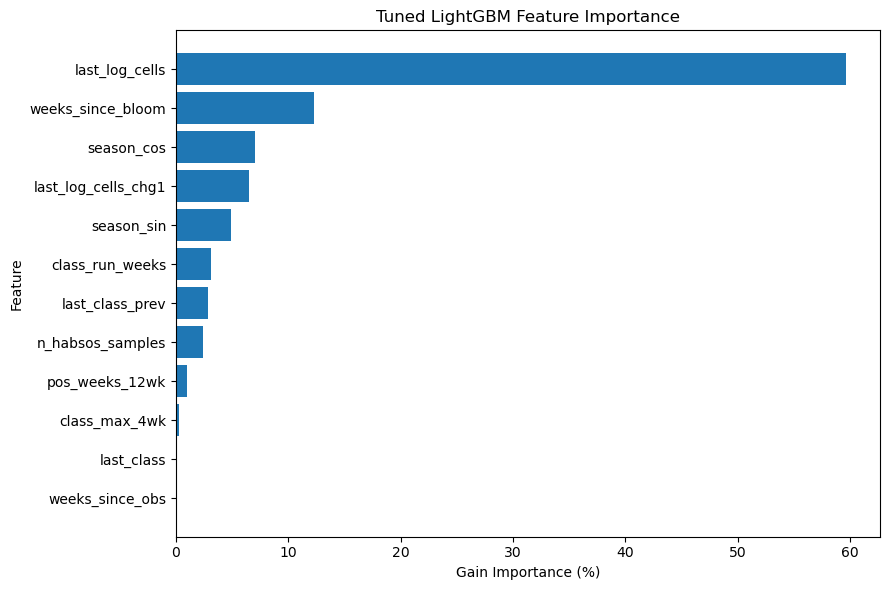

In [131]:
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance_Percent"]
)

plt.xlabel("Gain Importance (%)")
plt.ylabel("Feature")
plt.title("Tuned LightGBM Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "lightgbm_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

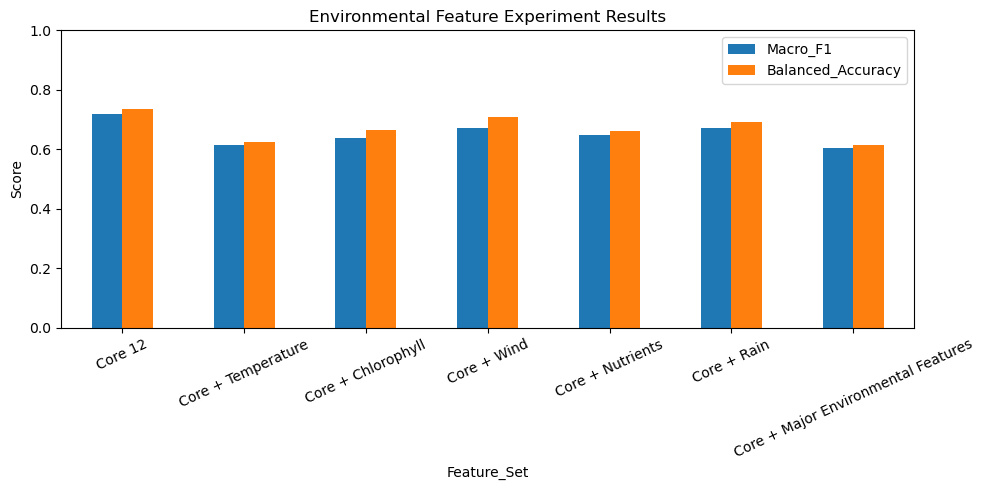

In [132]:
plot_env = environmental_results.set_index(
    "Feature_Set"
)[
    ["Macro_F1", "Balanced_Accuracy"]
]

ax = plot_env.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title(
    "Environmental Feature Experiment Results"
)

plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "environmental_feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

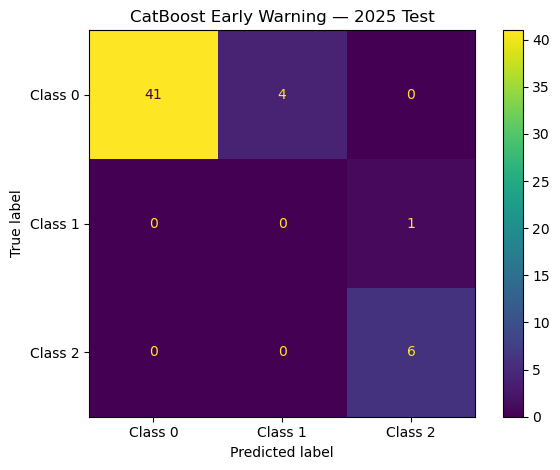

In [133]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test_2025,
    cat_test_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

disp.plot()

plt.title(
    "CatBoost Early Warning — 2025 Test"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "catboost_2025_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

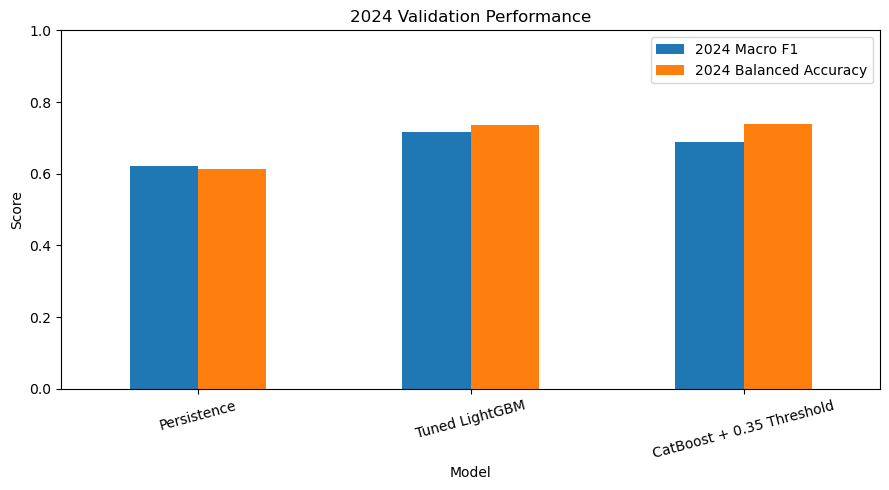

In [134]:
plot_df = final_model_summary[
    [
        "Model",
        "2024_Macro_F1",
        "2024_Balanced_Accuracy"
    ]
].set_index("Model")

plot_df.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("2024 Validation Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 21. Verify Saved Final Models

The final saved models are reloaded from disk and tested on one sample week
to confirm that the saved artifacts work correctly.


In [141]:
import joblib
import json
from catboost import CatBoostClassifier

# Load saved LightGBM
loaded_lgbm = joblib.load(
    SAVED_MODEL_DIR / "tuned_lightgbm_final_through_2024.pkl"
)

# Load saved CatBoost
loaded_catboost = CatBoostClassifier()

loaded_catboost.load_model(
    SAVED_MODEL_DIR / "catboost_early_warning_final_through_2024.cbm"
)

# Load system configuration
with open(
    SAVED_MODEL_DIR / "regional_hab_system_config.json",
    "r"
) as f:
    loaded_config = json.load(f)

print("All final artifacts loaded successfully.")
print("Early-warning threshold:", loaded_config["early_warning_threshold"])

All final artifacts loaded successfully.
Early-warning threshold: 0.35


In [142]:
sample_week = X_test_2025.iloc[[0]]

# -------------------------------
# LightGBM primary forecast
# -------------------------------

lgbm_prediction = int(
    loaded_lgbm.predict(sample_week)[0]
)

print(
    "Predicted Next-Week HAB Class:",
    f"Class {lgbm_prediction}"
)

Predicted Next-Week HAB Class: Class 2


In [143]:
cat_result = catboost_early_warning_output(
    loaded_catboost,
    sample_week,
    threshold=loaded_config["early_warning_threshold"]
)

HAB Early Warning: YES
Risk Probability: 96%
Warning Level: Class 2


In [ ]:
print("FINAL SAVED ARTIFACTS")
print("=" * 50)
for file in sorted(SAVED_MODEL_DIR.iterdir()):
    print("-", file.name)
